# Danakil (Dallol) vs Meridiani Planum: matched-resolution slope
Extends the sample terrain-features notebook. Changes: (1) Dallol added, (2) **median** slope, (3) every Earth site also computed at ~463 m pixels to match MOLA, (4) Mars slope from the MOLA 463 m DEM using **Mars' size** (the radius is read from the file's own CRS, 3396.19 km, about 59.3 km per degree, not Earth's 111 km).

Earth sites are block-averaged with separate factors in x and y so both pixel sides are close to 463 m (Copernicus tiles have wider longitude spacing at high latitude). At native ~30 m, slope over very flat ground (salt pans) is dominated by DEM noise, which is another reason to compare at 463 m.

Why 463 m matters: median slope depends strongly on pixel size. Compare Earth and Mars only at the same pixel size.
**In Colab** the MOLA file is downloaded automatically from USGS. **Locally**, set `MOLA_PATH` to the downloaded GeoTIFF.

Attribution: Copernicus DEM, produced using modified Copernicus data and information funded by the European Union. Mars: MOLA, NASA MGS (USGS Astrogeology).

In [1]:
import time
START_TIME = time.time()
import sys
if 'google.colab' in sys.modules:
    !pip -q install rasterio

zsh:1: command not found: pip


In [2]:
import os, re, sys, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from rasterio.merge import merge
from rasterio.windows import from_bounds
os.makedirs('charts', exist_ok=True)

In [3]:
SITES = [
    # name,               lat,       lon
    ("Dallol (Danakil)",   14.2400,   40.3000),   # verify on Google Maps!
    ("Atacama",           -24.0900,  -69.2500),   # verify!
    ("Haughton Crater",    75.3800,  -89.6700),   # verify!
    ("Death Valley",       36.2300, -116.7700),   # Badwater Basin area, verify!
]
MARS_SITE = ("Meridiani Planum", -1.95, 354.47)    # Opportunity landing site (same as -5.53 E)
# In Colab the file is downloaded automatically (below). Locally, set MOLA_PATH or put the GeoTIFF next to the notebook.
MOLA_PATH = os.environ.get("MOLA_PATH", "Mars_MGS_MOLA_DEM_mosaic_global_463m.tif")
MOLA_URLS = [  # ~2 GB. The USGS site blocks Python's default User-Agent (HTTP 403), so send a browser-like one.
    "https://asc-pds-services.s3.us-west-2.amazonaws.com/mosaic/Mars_MGS_MOLA_DEM_mosaic_global_463m.tif",  # USGS storage, direct
    "https://planetarymaps.usgs.gov/mosaic/Mars_MGS_MOLA_DEM_mosaic_global_463m.tif",                        # USGS site (redirects)
]

def download_mola(path):
    import urllib.request, shutil
    for url in MOLA_URLS:
        try:
            req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (danakil-mars-analog notebook)"})
            print(f"Downloading MOLA DEM (~2 GB, a few minutes) from {url} ...")
            with urllib.request.urlopen(req, timeout=60) as r, open(path + ".part", "wb") as f:
                size = int(r.headers.get("Content-Length", 0))
                shutil.copyfileobj(r, f, length=16 * 1024 * 1024)
            if size and os.path.getsize(path + ".part") != size:
                raise IOError("incomplete download")
            os.replace(path + ".part", path)   # only a complete file gets the real name
            print("Download complete.")
            return
        except Exception as ex:
            print(f"  failed: {ex}")
    raise RuntimeError("Could not download the MOLA DEM. Download it manually from USGS Astrogeology and upload it.")

if not os.path.exists(MOLA_PATH) and 'google.colab' in sys.modules:
    download_mola(MOLA_PATH)
BOX_KM = 20          # 10 km gives only ~21 px at 463 m, too few; use 20 km or more
TARGET_M = 463       # MOLA pixel size
R_MARS = 3_396_190.0 # m, fallback only: the radius is read from the MOLA file's CRS (MOLA uses 3396.19 km).
                     # 1 degree = 2*pi*R/360 = about 59.3 km (Earth: about 111.2 km)

Download complete.


In [4]:
BASE = "https://copernicus-dem-30m.s3.amazonaws.com"

def tile_url(lat_i, lon_i):
    ns = 'N' if lat_i >= 0 else 'S'
    ew = 'E' if lon_i >= 0 else 'W'
    name = f"Copernicus_DSM_COG_10_{ns}{abs(lat_i):02d}_00_{ew}{abs(lon_i):03d}_00_DEM"
    return f"{BASE}/{name}/{name}.tif"

def get_square(lat, lon, box_km=BOX_KM):
    half = box_km / 2 * 1000
    dlat = half / 110_540
    dlon = half / (111_320 * math.cos(math.radians(lat)))
    w, s, e, n = lon - dlon, lat - dlat, lon + dlon, lat + dlat
    srcs = []
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR', AWS_NO_SIGN_REQUEST='YES'):
        for la in range(math.floor(s), math.floor(n) + 1):
            for lo in range(math.floor(w), math.floor(e) + 1):
                try:
                    srcs.append(rasterio.open(tile_url(la, lo)))
                except Exception as ex:
                    print(f"  tile missing/failed ({la},{lo}): {ex}")
        if not srcs:
            raise RuntimeError("No tiles could be opened (ocean-only area or no internet?)")
        arr, tr = merge(srcs, bounds=(w, s, e, n))
        for sdat in srcs: sdat.close()
    return arr[0].astype('float64'), tr, (w, s, e, n)

def slope_from_spacing(z, dx_m, dy_m):
    dzdy, dzdx = np.gradient(z, dy_m, dx_m)
    return np.degrees(np.arctan(np.hypot(dzdx, dzdy)))

def earth_spacing(tr, lat):
    return abs(tr.a) * 111_320 * math.cos(math.radians(lat)), abs(tr.e) * 110_540

def block_mean(z, ky, kx=None):
    kx = ky if kx is None else kx
    h, w = (z.shape[0] // ky) * ky, (z.shape[1] // kx) * kx
    return np.nanmean(z[:h, :w].reshape(h // ky, ky, w // kx, kx), axis=(1, 3))

In [5]:
# EARTH: native (~30 m) and matched (~463 m)
rows = []
for name, lat, lon in SITES:
    print(f"Processing {name} ...")
    z, tr, bounds = get_square(lat, lon)
    dx, dy = earth_spacing(tr, lat)
    s_native = slope_from_spacing(z, dx, dy)
    kx, ky = max(1, round(TARGET_M / dx)), max(1, round(TARGET_M / dy))   # separate factors: pixels are not square in metres
    z_c = block_mean(z, ky, kx)
    s_463 = slope_from_spacing(z_c, dx * kx, dy * ky)
    rows.append(dict(site=name, planet="Earth", lat=lat, lon=lon, box_km=BOX_KM,
                     native_px_m=round(dx), coarse_px_m=round(dx * kx), coarse_px_y_m=round(dy * ky), coarse_grid=f"{z_c.shape[1]}x{z_c.shape[0]}",
                     mean_elev=round(np.nanmean(z), 1),
                     median_slope_native=round(float(np.nanmedian(s_native)), 2),
                     median_slope_463m=round(float(np.nanmedian(s_463)), 2),
                     mean_slope_463m=round(float(np.nanmean(s_463)), 2)))
    print(f"  native px ~{dx:.0f} x {dy:.0f} m, coarse px ~{dx*kx:.0f} x {dy*ky:.0f} m, grid {z_c.shape}")
earth = pd.DataFrame(rows)
earth

Processing Dallol (Danakil) ...


  native px ~30 x 31 m, coarse px ~450 x 461 m, grid (43, 44)
Processing Atacama ...


  native px ~28 x 31 m, coarse px ~452 x 461 m, grid (43, 44)
Processing Haughton Crater ...


  native px ~23 x 31 m, coarse px ~468 x 461 m, grid (43, 42)
Processing Death Valley ...


  native px ~25 x 31 m, coarse px ~474 x 461 m, grid (43, 42)


,site,planet,lat,lon,box_km,native_px_m,coarse_px_m,coarse_px_y_m,coarse_grid,mean_elev,median_slope_native,median_slope_463m,mean_slope_463m
0,Dallol (Danakil),Earth,14.24,40.30,20,30,450,461,44x43,-116.8,0.32,0.03,0.32
1,Atacama,Earth,-24.09,-69.25,20,28,452,461,44x43,2217.8,3.47,2.92,3.61
2,Haughton Crater,Earth,75.38,-89.67,20,23,468,461,42x43,219.2,4.79,2.11,2.58
3,Death Valley,Earth,36.23,-116.77,20,25,474,461,42x43,476.4,4.24,3.90,7.21


In [6]:
# MARS: MOLA 463 m (needs the GeoTIFF in the Colab session)
def crs_radius(crs, default=R_MARS):
    m = re.search(r'SPHEROID\["[^"]*",\s*([0-9.]+)', crs.to_wkt()) if crs is not None else None
    return float(m.group(1)) if m else default

def mars_window(path, lat, lon, box_km=BOX_KM):
    if not os.path.exists(path):
        raise FileNotFoundError(f"{path} not found: download the MOLA 463 m GeoTIFF and upload it / set MOLA_PATH")
    with rasterio.open(path) as src:
        R = crs_radius(src.crs)
        print("CRS:", src.crs, "| pixel:", src.res, "| bounds:", src.bounds, "| radius used:", R)   # CHECK this output
        half = box_km / 2 * 1000
        if src.crs is not None and src.crs.is_geographic:
            mdeg = 2 * math.pi * R / 360
            lo = lon
            if src.bounds.left >= 0 and lo < 0: lo += 360
            if src.bounds.right <= 180 and lo > 180: lo -= 360
            hl, hn = half / mdeg, half / (mdeg * math.cos(math.radians(lat)))
            win = from_bounds(lo - hn, lat - hl, lo + hn, lat + hl, src.transform)
            z = src.read(1, window=win, masked=True).astype('float64').filled(np.nan)
            dx, dy = abs(src.transform.a) * mdeg * math.cos(math.radians(lat)), abs(src.transform.e) * mdeg
        else:  # projected in metres (simple cylindrical): spacing is already in metres
            lon_c = lon if src.bounds.left > -1e6 else (lon - 360 if lon > 180 else lon)
            x0, y0 = R * math.radians(lon_c), R * math.radians(lat)
            coslat = math.cos(math.radians(lat))   # equirectangular x is true scale only at the equator
            win = from_bounds(x0 - half / coslat, y0 - half, x0 + half / coslat, y0 + half, src.transform)
            z = src.read(1, window=win, masked=True).astype('float64').filled(np.nan)
            dx, dy = abs(src.transform.a) * coslat, abs(src.transform.e)
    return z, dx, dy

name, lat, lon = MARS_SITE
zm, dxm, dym = mars_window(MOLA_PATH, lat, lon)
sm = slope_from_spacing(zm, dxm, dym)
mars = pd.DataFrame([dict(site=name, planet="Mars", lat=lat, lon=lon, box_km=BOX_KM,
                          native_px_m=round(dxm), coarse_px_m=round(dxm), coarse_px_y_m=round(dym), coarse_grid=f"{zm.shape[1]}x{zm.shape[0]}",
                          mean_elev=round(float(np.nanmean(zm)), 1),
                          median_slope_native=round(float(np.nanmedian(sm)), 2),
                          median_slope_463m=round(float(np.nanmedian(sm)), 2),
                          mean_slope_463m=round(float(np.nanmean(sm)), 2))])
mars

CRS: PROJCS["Equirectangular Mars",GEOGCS["GCS_Mars",DATUM["D_Mars",SPHEROID["Mars_localRadius",3396190,0]],PRIMEM["Reference_Meridian",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]]],PROJECTION["Equirectangular"],PARAMETER["standard_parallel_1",0],PARAMETER["central_meridian",0],PARAMETER["false_easting",0],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH]] | pixel: (463.0935415503709, 463.0935415503709) | bounds: BoundingBox(left=-10669675.197320545, bottom=-5334837.598660273, right=10669675.197320545, top=5334837.598660273) | radius used: 3396190.0


,site,planet,lat,lon,box_km,native_px_m,coarse_px_m,coarse_px_y_m,coarse_grid,mean_elev,median_slope_native,median_slope_463m,mean_slope_463m
0,Meridiani Planum,Mars,-1.95,354.47,20,463,463,463,43x43,-1386.9,0.26,0.26,0.29


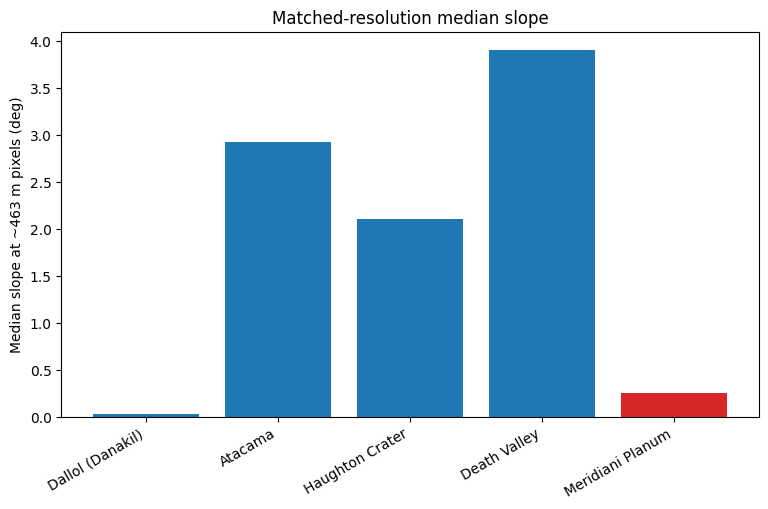

Run time: 0.21 h


,site,planet,lat,lon,box_km,native_px_m,coarse_px_m,coarse_px_y_m,coarse_grid,mean_elev,median_slope_native,median_slope_463m,mean_slope_463m
0,Dallol (Danakil),Earth,14.24,40.30,20,30,450,461,44x43,-116.8,0.32,0.03,0.32
1,Atacama,Earth,-24.09,-69.25,20,28,452,461,44x43,2217.8,3.47,2.92,3.61
2,Haughton Crater,Earth,75.38,-89.67,20,23,468,461,42x43,219.2,4.79,2.11,2.58
3,Death Valley,Earth,36.23,-116.77,20,25,474,461,42x43,476.4,4.24,3.90,7.21
4,Meridiani Planum,Mars,-1.95,354.47,20,463,463,463,43x43,-1386.9,0.26,0.26,0.29


In [7]:
df = pd.concat([earth, mars], ignore_index=True)
df.to_csv('results.csv', index=False)
fig, ax = plt.subplots(figsize=(9, 5))
colors = ['tab:red' if p == 'Mars' else 'tab:blue' for p in df.planet]
ax.bar(df.site, df.median_slope_463m, color=colors)
ax.set_ylabel('Median slope at ~463 m pixels (deg)'); ax.set_title('Matched-resolution median slope')
plt.xticks(rotation=30, ha='right'); fig.savefig('charts/median_slope_463m.png', dpi=150, bbox_inches='tight'); plt.show()
print(f"Run time: {(time.time()-START_TIME)/3600:.2f} h"); df